# Univariate Time Series Models III
**HS 821 · Lectures 9 · Topics in Time Series Econometrics**

**Sunil Paul**

October 2026 · R 4.6

Lectures 6–8 treated the parameters of an ARMA model as **known**: every ACF, PACF and impulse response was a population object. In practice we observe a single realization $y_1,\dots,y_T$ and must work backwards, from data to model. This lecture introduces the **Box–Jenkins cycle**:

1. **Identification** — use the sample ACF and PACF to shortlist a few candidate orders $(p,q)$ (Section 1).
2. **Estimation** — fit each candidate by the method of moments, least squares, maximum likelihood or Bayesian methods (Sections 2–4), and compare candidates with information criteria (Section 5).
3. **Diagnostic checking** — test whether the residuals behave like white noise; if not, return to step 1 (Section 6).
4. **Forecasting and evaluation** — forecast with the accepted model and judge it out of sample (Sections 7–8).

Section 9 extends the toolkit to seasonal data, and Section 10 runs the whole cycle on a classic real series: Yule's sunspot numbers. Appendix A lists the mathematical prerequisites with videos and readings.

*Notation follows Lectures 6–8: $Y_t=c+\phi_1Y_{t-1}+\cdots+\phi_pY_{t-p}+\varepsilon_t+\beta_1\varepsilon_{t-1}+\cdots+\beta_q\varepsilon_{t-q}$, or $\phi(L)Y_t=c+\beta(L)\varepsilon_t$, with mean $\mu=c/(1-\phi_1-\cdots-\phi_p)$, $X_t=Y_t-\mu$ and Wold weights $\psi_j$. Lower-case $y_t$ denotes observed data. All series here are stationary; unit roots, differencing and ARIMA models come in a later lecture.*

## Setup

We reuse the plotting helpers of Lectures 6–8 (the correlogram helpers gain an optional `by` argument for the spacing of lag labels) and add three new ones: `resid_panel()` for diagnostic checking, `fan_plot()` for forecast intervals and `mcmc_plot()` for Bayesian output. All estimation uses base-R `stats`:

- `ar.yw()`, `ar.ols()` — Yule–Walker and least-squares estimation of AR models;
- `arima()` — conditional-sum-of-squares (`method = "CSS"`) or exact Gaussian maximum likelihood (`method = "ML"`) for ARMA models;
- `optim()` — numerical maximization of a likelihood we write ourselves;
- `Box.test()` — Box–Pierce and Ljung–Box portmanteau tests;
- `predict()` — point forecasts and their standard errors.

> **R convention.** `arima()` reports the **mean** $\mu$ under the label `intercept`, not the constant $c$; recover $c=\mu(1-\phi_1-\cdots-\phi_p)$ when needed. Its MA polynomial is $1+\beta_1L+\cdots+\beta_qL^q$, the same sign convention as ours.

In [1]:
# ------------------------------------------------------------------
# Setup: plotting helpers (Lectures 6-8 helpers + three new ones)
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Time-series line plot; optional dashed reference line at the mean.
ts_plot <- function(x, mu = NULL, title = NULL) {
  time_idx <- if (is.ts(x)) as.numeric(time(x)) else seq_along(x)
  df <- data.frame(time = time_idx, value = as.numeric(x))
  p <- ggplot(df, aes(time, value)) +
    theme_classic() + geom_line() + labs(x = "Time", y = NULL, title = title)
  if (!is.null(mu)) p <- p + geom_hline(yintercept = mu, linetype = "dashed")
  p
}

# Theoretical ACF of an ARMA process, lags 1..L (lag 0 dropped).
acf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL, by = 3) {
  rho <- ARMAacf(ar = ar, ma = ma, lag.max = L)[-1]
  df  <- data.frame(lag = seq_len(L), acf = as.numeric(rho))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "ACF", title = title)
}

# Theoretical PACF of an ARMA process, lags 1..L.
pacf_plot <- function(ar = numeric(0), ma = numeric(0), L = 15, title = NULL, by = 3) {
  pac <- ARMAacf(ar = ar, ma = ma, lag.max = L, pacf = TRUE)
  df  <- data.frame(lag = seq_len(L), pacf = as.numeric(pac))
  ggplot(df, aes(lag, pacf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = pacf), linewidth = 1) +
    geom_point(size = 2) +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "PACF", title = title)
}

# Theoretical impulse response = Wold coefficients psi_0=1, psi_1, psi_2, ...
irf_plot <- function(ar = numeric(0), ma = numeric(0), h = 20, title = NULL) {
  psi <- c(1, ARMAtoMA(ar = ar, ma = ma, lag.max = h))
  df  <- data.frame(horizon = 0:h, response = psi)
  ggplot(df, aes(horizon, response)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = horizon, y = 0, yend = response)) +
    geom_point() +
    scale_x_continuous(breaks = seq(0, h, by = 4)) +
    labs(x = "Horizon after a unit innovation", y = "Response", title = title)
}

# Sample ACF / PACF with approximate +/- 2/sqrt(T) bands.
sample_acf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- acf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag)[-1], acf = as.numeric(a$acf)[-1])
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample ACF", title = title)
}

sample_pacf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- pacf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = as.numeric(a$lag), acf = as.numeric(a$acf))
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample PACF", title = title)
}

# Roots of a lag polynomial on the complex plane, with the unit circle.
roots_plot <- function(roots, title = NULL) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots),
                      outside = ifelse(Mod(roots) > 1, "outside", "inside"))
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = outside), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red"),
                        name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# NEW. Residual diagnostics for an arima() fit: residual series, residual ACF,
# and Ljung-Box p-values for K = p+q+1, ..., L with the corrected df = K - p - q.
resid_panel <- function(fit, L = 20, title = NULL) {
  e     <- as.numeric(residuals(fit))
  fitdf <- sum(fit$arma[1:4])                    # p + q (+ seasonal P + Q)
  lags  <- (fitdf + 1):L
  pv    <- sapply(lags, function(k)
    Box.test(e, lag = k, type = "Ljung-Box", fitdf = fitdf)$p.value)
  g1 <- ts_plot(e, mu = 0, title = paste(title, "- residuals"))
  g2 <- sample_acf_plot(e, L = L, title = "Residual ACF")
  g3 <- ggplot(data.frame(lag = lags, p = pv), aes(lag, p)) + theme_classic() +
    geom_point(size = 2) +
    geom_hline(yintercept = 0.05, linetype = "dashed", colour = "red") +
    scale_y_continuous(limits = c(0, 1)) +
    labs(x = "Number of lags K", y = "p-value", title = "Ljung-Box p-values")
  grid.arrange(g1, g2, g3, ncol = 3)
}

# NEW. Fan chart: last n_show observations, point forecast, 80% and 95% bands.
# t_end is the time index of the last observation.
fan_plot <- function(y, mean, lo80, hi80, lo95, hi95, n_show = 60,
                     t_end = length(y), title = NULL) {
  y   <- as.numeric(y); h <- length(mean)
  obs <- data.frame(time = (t_end - n_show + 1):t_end, value = tail(y, n_show))
  fc  <- data.frame(time = t_end + 1:h, mean = as.numeric(mean),
                    lo80 = as.numeric(lo80), hi80 = as.numeric(hi80),
                    lo95 = as.numeric(lo95), hi95 = as.numeric(hi95))
  ggplot() + theme_classic() +
    geom_ribbon(data = fc, aes(time, ymin = lo95, ymax = hi95), fill = "grey85") +
    geom_ribbon(data = fc, aes(time, ymin = lo80, ymax = hi80), fill = "grey65") +
    geom_line(data = obs, aes(time, value)) +
    geom_line(data = fc, aes(time, mean), linetype = "dashed") +
    labs(x = "Time", y = NULL, title = title)
}

# NEW. MCMC output for one parameter: trace plot and posterior histogram
# (solid line: posterior mean; optional dashed red line: true value).
mcmc_plot <- function(draws, name, true = NULL) {
  df <- data.frame(iter = seq_along(draws), value = as.numeric(draws))
  g1 <- ggplot(df, aes(iter, value)) + theme_classic() +
    geom_line(linewidth = 0.2) +
    labs(x = "Iteration (after burn-in)", y = name, title = paste("Trace:", name))
  g2 <- ggplot(df, aes(value)) + theme_classic() +
    geom_histogram(bins = 40, fill = "grey70", colour = "white") +
    geom_vline(xintercept = mean(df$value)) +
    labs(x = name, y = "Count", title = paste("Posterior:", name))
  if (!is.null(true))
    g2 <- g2 + geom_vline(xintercept = true, linetype = "dashed", colour = "red")
  list(g1, g2)
}

# 1&nbsp;&nbsp;Identification: the sample correlogram

## Sample moments

Given data $y_1,\dots,y_T$, the population moments of Lecture 5 are estimated by their sample analogues:

$$
\bar y=\frac1T\sum_{t=1}^{T}y_t,
\qquad
\hat\gamma_j=\frac1T\sum_{t=j+1}^{T}(y_t-\bar y)(y_{t-j}-\bar y),
\qquad
\hat\rho_j=\frac{\hat\gamma_j}{\hat\gamma_0},
\qquad j=0,1,\dots,T-1.
$$

Two details matter.

- The divisor is $T$, not $T-j$. This shrinks $\hat\gamma_j$ slightly towards zero at long lags, but it guarantees that the sample autocovariance matrix $\hat\Gamma_p=[\hat\gamma_{|i-j|}]$ is positive definite. That is why the Yule–Walker estimator of Section 2 always delivers a stationary AR model.
- Long lags rest on few pairs of observations. A common rule is to inspect lags up to about $T/4$.

The **sample PACF** $\hat\phi_{jj}$ is the last coefficient in the regression of $y_t$ on $y_{t-1},\dots,y_{t-j}$ (Lectures 6–8, Section 4). Equivalently, it is obtained from the $\hat\rho_j$ by the Durbin–Levinson recursion.

## How large is "large"? Sampling distributions

**White noise.** If $Y_t$ is i.i.d. with finite variance, then for each $j\ge1$

$$
\hat\rho_j\;\overset{a}{\sim}\;N\!\left(0,\tfrac1T\right),
$$

and estimates at different lags are asymptotically independent. Approximate 95% bands are therefore $\pm2/\sqrt T$, the dashed red lines in `sample_acf_plot()`. We reject $H_0:\rho_j=0$ when $|\hat\rho_j|>2/\sqrt T$.

**MA($q$): Bartlett's formula.** If $Y_t$ is MA($q$), then for lags beyond the cut-off

$$
\operatorname{Var}(\hat\rho_j)\approx\frac1T\Big(1+2\sum_{i=1}^{q}\rho_i^2\Big),
\qquad j>q .
$$

The bands widen with $q$. This gives a sequential test of the MA order: under $H_0$: MA($q$), autocorrelations beyond lag $q$ should lie within $\pm2\sqrt{\operatorname{Var}(\hat\rho_j)}$, with $\rho_i$ replaced by $\hat\rho_i$. In R, `acf(x, ci.type = "ma")` draws these bands.

**AR($p$): Quenouille's result.** If $Y_t$ is AR($p$), then

$$
\hat\phi_{jj}\;\overset{a}{\sim}\;N\!\left(0,\tfrac1T\right),
\qquad j>p,
$$

so the $\pm2/\sqrt T$ bands on the sample PACF test the AR order directly.

> **Two cautions.** (i) With 20 lags and 5% bands, about one spike will cross the bands by chance even for white noise. (ii) Sample autocorrelations of a dependent series are correlated *across lags*, so a sample ACF looks smoother, with longer waves, than its population counterpart. Do not chase isolated spikes at long, uninterpretable lags.

### Hands on- SACF and SPACF 
We draw (a) white noise and (b) an MA(1) with $\beta=0.7$, both with $T=100$. Predict:

1. For white noise, roughly how many of the first 20 sample autocorrelations should cross $\pm2/\sqrt{T}=\pm0.2$?
2. For the MA(1), $\rho_1=\beta/(1+\beta^2)=0.47$. How much wider are Bartlett's bands for lags $j>1$ than the naive $\pm0.2$?
3. Which of the four panels should show a decaying pattern?

Naive band: +/- 0.200   Bartlett band for j > 1: +/- 0.240
White-noise lags outside +/- 2/sqrt(T): 0 of 20


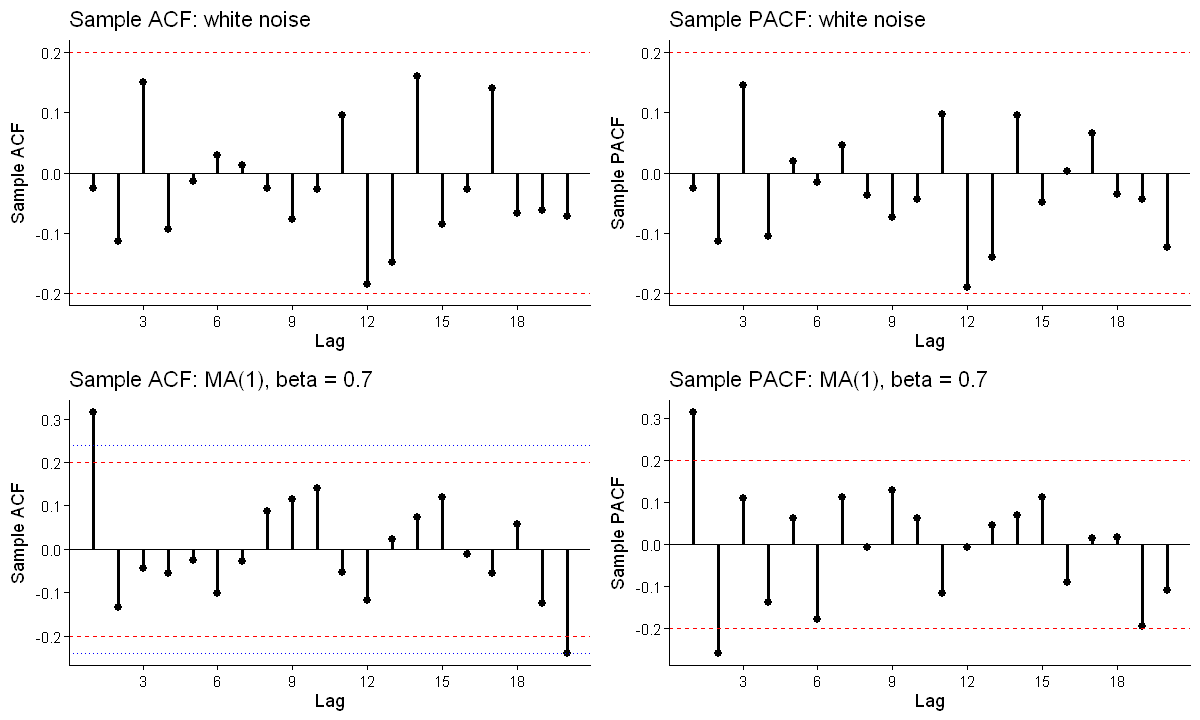

In [2]:
# Sample ACF/PACF of white noise and of an MA(1); naive (red) and Bartlett (blue) bands
set.seed(123)
T  <- 100
wn <- rnorm(T)
ma <- arima.sim(model = list(ma = 0.7), n = T)

rho1     <- 0.7 / (1 + 0.7^2)
bartlett <- 2 * sqrt((1 + 2 * rho1^2) / T)
cat(sprintf("Naive band: +/- %.3f   Bartlett band for j > 1: +/- %.3f\n", 2 / sqrt(T), bartlett))
cat("White-noise lags outside +/- 2/sqrt(T):",
    sum(abs(acf(wn, plot = FALSE, lag.max = 20)$acf[-1]) > 2 / sqrt(T)), "of 20\n")
# you may also try with `acf(x, plot = FALSE, lag.max = L)`

g_ma <- sample_acf_plot(ma, title = "Sample ACF: MA(1), beta = 0.7") +
  geom_hline(yintercept = c(bartlett, -bartlett), linetype = "dotted", colour = "blue")
grid.arrange(
  sample_acf_plot(wn,  title = "Sample ACF: white noise"),
  sample_pacf_plot(wn, title = "Sample PACF: white noise"),
  g_ma,
  sample_pacf_plot(ma, title = "Sample PACF: MA(1), beta = 0.7"),
  ncol = 2
)

**Reading the graphs**

- For white noise none of the 20 sample autocorrelations crosses the bands in this draw, although lags 12 and 14 come close. One crossing in twenty would have been entirely normal.
- For the MA(1) the sample ACF has one large spike at lag 1 — 0.32, well below the population value 0.47, a reminder of sampling noise at $T=100$ — and then stays inside the bands, apart from an isolated spike at lag 20 that just reaches Bartlett's band. That is exactly the kind of long, uninterpretable lag not to chase. Bartlett's bands (dotted blue) are 20% wider than the naive ones here; with several large $\hat\rho_i$ the correction matters more.
- The MA(1) sample PACF starts with a positive spike, then a negative one, and dies out — the alternating decay of an MA(1) with $\beta>0$, read through sampling noise.

## Portmanteau tests: Box–Pierce and Ljung–Box

Instead of testing one lag at a time we can test the first $K$ autocorrelations **jointly**, $H_0:\rho_1=\cdots=\rho_K=0$:

$$
Q_{BP}(K)=T\sum_{k=1}^{K}\hat\rho_k^{\,2},
\qquad
Q_{LB}(K)=T(T+2)\sum_{k=1}^{K}\frac{\hat\rho_k^{\,2}}{T-k}.
$$

Both are approximately $\chi^2(K)$ under $H_0$; reject at 5% if $Q(K)>\chi^2_{0.95}(K)$. The Ljung–Box weights $(T+2)/(T-k)>1$ correct the Box–Pierce statistic, whose $\chi^2$ approximation is poor in small samples (it rejects too rarely).

**On residuals the degrees of freedom change.** When the test is applied to the residuals of an estimated ARMA($p,q$), the $p+q$ estimated coefficients absorb part of the autocorrelation, and

$$
Q(K)\;\overset{a}{\sim}\;\chi^2(K-p-q)
\qquad\text{(in R: } \texttt{Box.test(e, lag = K, type = "Ljung-Box", fitdf = p + q)}\text{)}.
$$

**Choosing $K$.** Small $K$ lacks power against dependence at longer lags; large $K$ dilutes the test. Common choices are $K\approx10$ for non-seasonal data and $K\approx2s$ for seasonal data with period $s$; reporting several values of $K$ is good practice, as `resid_panel()` does.

### Predict before you simulate

We generate 2000 white-noise samples of length $T=50$ and test with $K=10$ at the 5% level. Which test should reject close to 5% of the time, and which less often?

In [3]:
# Size of Box-Pierce vs Ljung-Box under white noise (T = 50, K = 10, nominal 5%)
set.seed(123)
reject <- replicate(2000, {
  e <- rnorm(50)
  c(BoxPierce = Box.test(e, lag = 10, type = "Box-Pierce")$p.value < 0.05,
    LjungBox  = Box.test(e, lag = 10, type = "Ljung-Box")$p.value  < 0.05)
})
cat("Empirical rejection rates under H0:\n"); print(round(rowMeans(reject), 3))

# Power: the same test applied to an AR(1) with phi = 0.5
set.seed(123)
Box.test(arima.sim(model = list(ar = 0.5), n = 100), lag = 10, type = "Ljung-Box")

Empirical rejection rates under H0:
BoxPierce  LjungBox 
    0.026     0.052 



	Box-Ljung test

data:  arima.sim(model = list(ar = 0.5), n = 100)
X-squared = 53.741, df = 10, p-value = 5.421e-08


**Reading the output.** The Ljung–Box test rejects about 5% of the time under the null, as it should; Box–Pierce rejects only about half as often — it is *undersized* at $T=50$. Against a genuinely dependent series the Ljung–Box statistic is enormous. This is why software and practice default to Ljung–Box.

## An identification checklist

1. **Plot the series.** Look for trends, breaks, outliers, changing variance and seasonality.
2. **Transform if necessary.** Logs or square roots stabilize a variance that grows with the level (Section 10 uses square roots); differencing removes stochastic trends (later lecture).
3. **Compute the sample ACF and PACF** and compare them with the fingerprint table of Lectures 6–8, Section 7.
4. **Shortlist two to four candidates**, favouring small models (parsimony). Mixed ARMA models are hard to separate by eye, because both the ACF and the PACF decay.
5. **Carry all candidates into estimation**, and let information criteria (Section 5), diagnostics (Section 6) and out-of-sample performance (Section 8) decide.

# 2&nbsp;&nbsp;Estimation I: moments and least squares

## The estimation problem

For an ARMA($p,q$) we must estimate

$$
\boldsymbol\theta=(c,\;\phi_1,\dots,\phi_p,\;\beta_1,\dots,\beta_q,\;\sigma^2)'.
$$

Three features make this harder than cross-section regression:

- **Dependence.** Observations are correlated, so the joint density of the sample is not the product of the marginal densities.
- **Lagged regressors are not strictly exogenous.** $Y_{t-1}$ is uncorrelated with $\varepsilon_t$ but correlated with $\varepsilon_{t-1},\varepsilon_{t-2},\dots$, which biases least squares in finite samples.
- **MA terms are unobserved.** The lagged shocks $\varepsilon_{t-j}$ must be reconstructed from the data, which makes estimation nonlinear.

The four approaches covered in Sections 2–4:

| Approach | Idea | Natural for |
|---|---|---|
| Method of moments (Yule–Walker) | match population and sample autocovariances | pure AR |
| Least squares (OLS, CSS) | minimize the sum of squared one-step errors, conditioning on initial values | AR (OLS); ARMA (nonlinear CSS) |
| Exact maximum likelihood | maximize the full Gaussian joint density | any ARMA |
| Bayesian | combine the likelihood with a prior to obtain a posterior distribution | any ARMA; small samples |

## Method of moments: the Yule–Walker equations

For a mean-corrected AR($p$), multiply $X_t=\phi_1X_{t-1}+\cdots+\phi_pX_{t-p}+\varepsilon_t$ by $X_{t-j}$, $j=1,\dots,p$, and take expectations. This yields the Yule–Walker equations of Lectures 6–8 in matrix form:

$$
\underbrace{\begin{bmatrix}
\gamma_0 & \gamma_1 & \cdots & \gamma_{p-1}\\
\gamma_1 & \gamma_0 & \cdots & \gamma_{p-2}\\
\vdots & & \ddots & \vdots\\
\gamma_{p-1} & \gamma_{p-2} & \cdots & \gamma_0
\end{bmatrix}}_{\Gamma_p}
\begin{bmatrix}\phi_1\\ \phi_2\\ \vdots\\ \phi_p\end{bmatrix}
=
\underbrace{\begin{bmatrix}\gamma_1\\ \gamma_2\\ \vdots\\ \gamma_p\end{bmatrix}}_{\boldsymbol\gamma_p},
\qquad
\sigma^2=\gamma_0-\boldsymbol\phi'\boldsymbol\gamma_p .
$$

Replacing population moments by sample moments gives the **Yule–Walker estimator**

$$
\boxed{\;\hat{\boldsymbol\phi}_{YW}=\hat\Gamma_p^{-1}\hat{\boldsymbol\gamma}_p,
\qquad
\hat\sigma^2=\hat\gamma_0-\hat{\boldsymbol\phi}'\hat{\boldsymbol\gamma}_p,
\qquad
\hat c=\bar y\,(1-\hat\phi_1-\cdots-\hat\phi_p).\;}
$$

For an AR(1), $\hat\phi=\hat\rho_1$. For an AR(2), solving the two equations gives

$$
\hat\phi_1=\frac{\hat\rho_1(1-\hat\rho_2)}{1-\hat\rho_1^2},
\qquad
\hat\phi_2=\frac{\hat\rho_2-\hat\rho_1^2}{1-\hat\rho_1^2}.
$$

**Properties.**

- Closed form, no iteration.
- Because $\hat\Gamma_p$ is positive definite, $\hat{\boldsymbol\phi}_{YW}$ is **always stationary**.
- $\sqrt T(\hat{\boldsymbol\phi}_{YW}-\boldsymbol\phi)\overset{d}{\to}N(\mathbf 0,\;\sigma^2\Gamma_p^{-1})$ — the same asymptotic distribution as maximum likelihood, so Yule–Walker is asymptotically efficient for pure AR models. For an AR(1), $\operatorname{Var}(\hat\phi)\approx(1-\phi^2)/T$.
- In small samples it is biased towards zero, most severely when roots are close to the unit circle.
- The last coefficient $\hat\phi_{pp}$ is exactly the sample PACF at lag $p$: Yule–Walker and the PACF are the same calculation.

In [4]:
# Yule-Walker by hand for the AR(2) realization of Lectures 6-8 (Section 4: model A)
set.seed(2024)
y_ar2 <- arima.sim(model = list(ar = c(0.5, 0.25)), n = 250)

g      <- acf(y_ar2, type = "covariance", plot = FALSE, lag.max = 2)$acf[, 1, 1]  # gamma_0..gamma_2
Gam    <- matrix(c(g[1], g[2], g[2], g[1]), 2, 2)
phi_yw <- solve(Gam, g[2:3])
s2_yw  <- g[1] - sum(phi_yw * g[2:3])
r      <- g / g[1]

cat("True (phi1, phi2)            : 0.5000 0.2500\n")
cat("Yule-Walker, matrix form     :", round(phi_yw, 4), "  sigma2 =", round(s2_yw, 4), "\n")
cat("Yule-Walker, AR(2) formulas  :", round(c(r[2] * (1 - r[3]) / (1 - r[2]^2),
                                            (r[3] - r[2]^2) / (1 - r[2]^2)), 4), "\n")
cat("ar.yw()                      :", round(ar.yw(y_ar2, order.max = 2, aic = FALSE)$ar, 4), "\n")
cat("Sample PACF at lag 2         :", round(pacf(y_ar2, plot = FALSE)$acf[2], 4), "  (= phi_22)\n")
cat("Asymptotic s.e.              :", round(sqrt(diag(s2_yw * solve(Gam) / length(y_ar2))), 4), "\n")

True (phi1, phi2)            : 0.5000 0.2500
Yule-Walker, matrix form     : 0.5224 0.1716   sigma2 = 0.927 
Yule-Walker, AR(2) formulas  : 0.5224 0.1716 
ar.yw()                      : 0.5224 0.1716 
Sample PACF at lag 2         : 0.1716   (= phi_22)
Asymptotic s.e.              : 0.0623 0.0623 


### MA models resist the method of moments

For an MA(1), $\rho_1=\beta/(1+\beta^2)$. Matching moments gives the quadratic $\hat\rho_1\beta^2-\beta+\hat\rho_1=0$, whose invertible root is

$$
\hat\beta_{MM}=\frac{1-\sqrt{1-4\hat\rho_1^{\,2}}}{2\hat\rho_1}.
$$

A real solution exists only if $|\hat\rho_1|\le0.5$, because $|\rho_1|\le0.5$ for every MA(1). When $\beta$ is large, sampling noise often pushes $|\hat\rho_1|$ above 0.5, and the estimator simply does not exist. Even when it exists it is inefficient. Moment estimators are useful mainly as **starting values** for likelihood-based estimation.

**Predict:** for $\beta=0.9$ (so $\rho_1=0.497$) and $T=100$, in what share of samples does $\hat\beta_{MM}$ fail to exist?

Share of samples with |rho1_hat| > 0.5 (no real solution): 36.4%


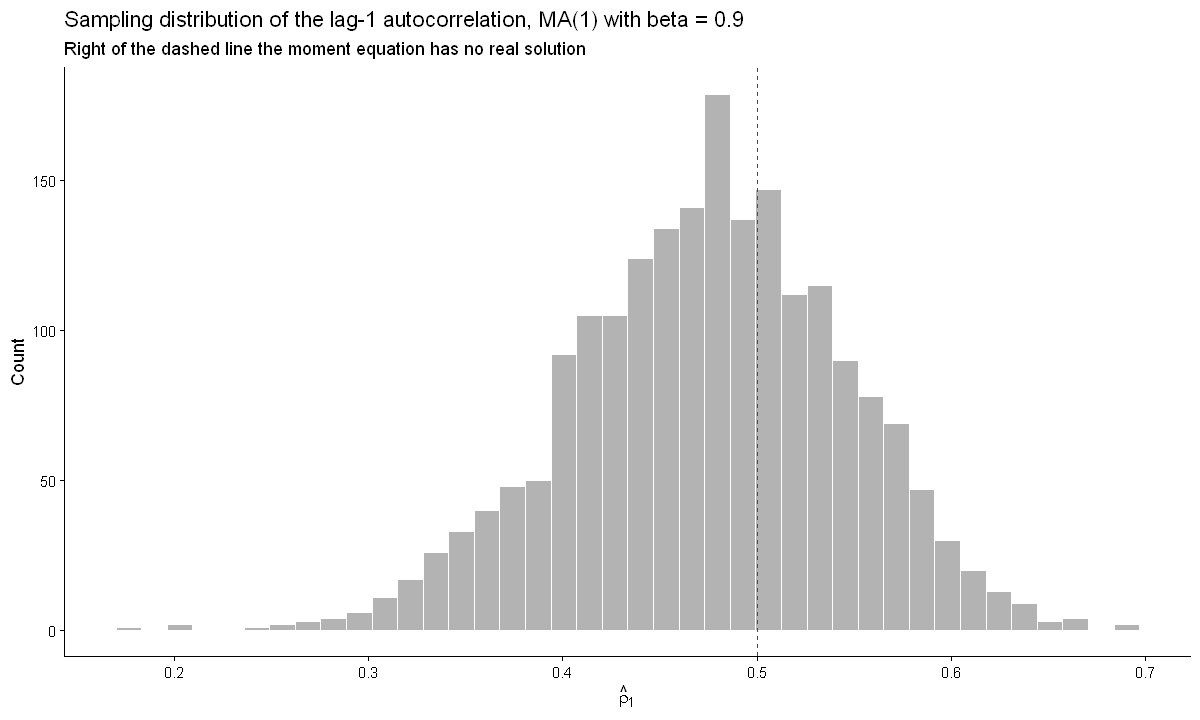

In [5]:
# How often does the MA(1) moment estimator fail to exist? (beta = 0.9, T = 100)
set.seed(123)
rho1_hat <- replicate(2000, {
  y <- arima.sim(model = list(ma = 0.9), n = 100)
  acf(y, plot = FALSE)$acf[2]
})
cat(sprintf("Share of samples with |rho1_hat| > 0.5 (no real solution): %.1f%%\n",
            100 * mean(abs(rho1_hat) > 0.5)))

ggplot(data.frame(r = rho1_hat), aes(r)) + theme_classic() +
  geom_histogram(bins = 40, fill = "grey70", colour = "white") +
  geom_vline(xintercept = 0.5, linetype = "dashed", colour = "red") +
  labs(x = expression(hat(rho)[1]), y = "Count",
       title = "Sampling distribution of the lag-1 autocorrelation, MA(1) with beta = 0.9",
       subtitle = "Right of the dashed line the moment equation has no real solution")

**Reading the output.** In about a third of the samples the moment estimator does not exist at all, even though the true model is a perfectly well-behaved invertible MA(1). Likelihood-based estimators have no such problem, because they use the whole autocorrelation structure rather than a single moment.

## Least squares

### OLS for AR($p$)

Conditioning on the first $p$ observations, an AR($p$) is a linear regression for $t=p+1,\dots,T$:

$$
Y_t=\mathbf x_t'\mathbf b+\varepsilon_t,
\qquad
\mathbf x_t=(1,\;Y_{t-1},\dots,Y_{t-p})',
\qquad
\mathbf b=(c,\;\phi_1,\dots,\phi_p)',
$$

$$
\hat{\mathbf b}_{OLS}=\Big(\sum_{t=p+1}^{T}\mathbf x_t\mathbf x_t'\Big)^{-1}\sum_{t=p+1}^{T}\mathbf x_tY_t,
\qquad
\hat\sigma^2=\frac{1}{T-p}\sum_{t=p+1}^{T}\hat\varepsilon_t^{\,2}.
$$

Because $E(\varepsilon_t\mid\mathbf x_t)=0$ (contemporaneous exogeneity), OLS is **consistent and asymptotically normal**, and the usual OLS standard errors are valid in large samples. But the regressors are **not strictly exogenous**: $\varepsilon_t$ feeds into the future regressors $Y_t,Y_{t+1},\dots$, so $E(\hat{\mathbf b})\ne\mathbf b$ in finite samples. For an AR(1) with an estimated intercept the classic approximation (Kendall 1954; Marriott and Pope 1954) is

$$
E(\hat\phi_{OLS})-\phi\;\approx\;-\frac{1+3\phi}{T}.
$$

The bias is downward and grows with persistence: **OLS understates persistence**, so estimated half-lives are too short.

### Predict before you simulate

We draw 2000 samples from an AR(1) with $\phi=0.9$ at $T=25,50,100,250$ and estimate $\phi$ by OLS. What sign does the bias have? Roughly how large is it at $T=25$?

   T mean_phi_hat    bias approx_bias
  25       0.7299 -0.1701     -0.1480
  50       0.8179 -0.0821     -0.0740
 100       0.8603 -0.0397     -0.0370
 250       0.8837 -0.0163     -0.0148


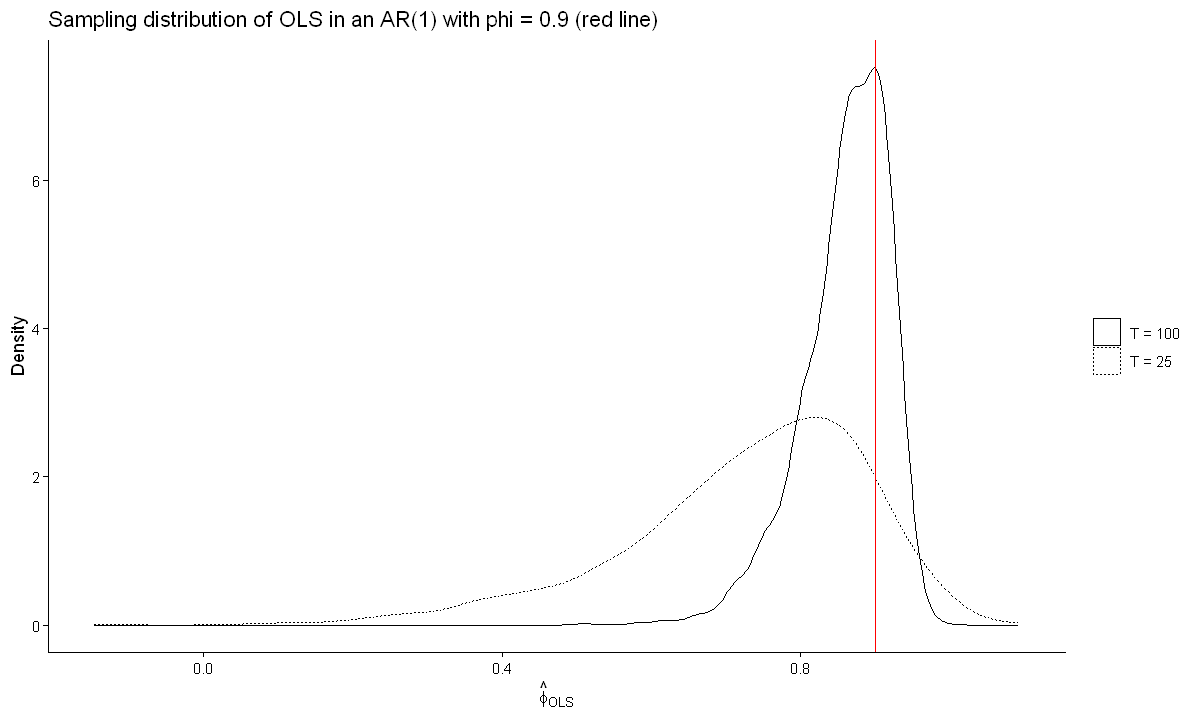

In [6]:
# Monte Carlo: finite-sample bias of OLS in an AR(1) with phi = 0.9
set.seed(123)
phi  <- 0.9
Ts   <- c(25, 50, 100, 250)
ests <- lapply(Ts, function(T) replicate(2000, {
  y <- arima.sim(model = list(ar = phi), n = T)
  coef(lm(y[-1] ~ y[-T]))[2]
}))

bias_tab <- data.frame(T = Ts,
                       mean_phi_hat = sapply(ests, mean),
                       bias         = sapply(ests, mean) - phi,
                       approx_bias  = -(1 + 3 * phi) / Ts)
print(round(bias_tab, 4), row.names = FALSE)

dens <- do.call(rbind, lapply(1:2, function(i)
  data.frame(phi_hat = ests[[c(1, 3)[i]]], T = paste("T =", Ts[c(1, 3)[i]]))))
ggplot(dens, aes(phi_hat, linetype = T)) + theme_classic() +
  geom_density() +
  geom_vline(xintercept = phi, colour = "red") +
  labs(x = expression(hat(phi)[OLS]), y = "Density", linetype = NULL,
       title = "Sampling distribution of OLS in an AR(1) with phi = 0.9 (red line)")

**Reading the output.** The bias is negative at every sample size and roughly halves each time $T$ doubles, as the $-(1+3\phi)/T$ approximation predicts. At $T=25$ the typical estimate is about 0.73 rather than 0.9, and the distribution is long-tailed to the left. With quarterly macro data, 25 years is $T=100$, where the bias is still about $-0.04$: enough to shorten an estimated half-life noticeably.

### Conditional least squares for ARMA($p,q$)

With MA terms the lagged shocks are unobserved, so we build them recursively. For trial values of $(c,\boldsymbol\phi,\boldsymbol\beta)$,

$$
\varepsilon_t(\boldsymbol\phi,\boldsymbol\beta)=Y_t-c-\sum_{i=1}^{p}\phi_iY_{t-i}-\sum_{j=1}^{q}\beta_j\,\varepsilon_{t-j}(\boldsymbol\phi,\boldsymbol\beta),
\qquad t=p+1,\dots,T,
$$

with pre-sample shocks set to zero. **Conditional sum of squares (CSS)** minimizes $S(c,\boldsymbol\phi,\boldsymbol\beta)=\sum_t\varepsilon_t^2$. The problem is nonlinear in $\boldsymbol\beta$, so it is solved numerically (`arima(..., method = "CSS")`).

> **Invertibility is what makes CSS work.** An error in the arbitrary starting value $\varepsilon_p=0$ is carried into $\varepsilon_t$ multiplied by $(-\beta)^{t-p}$ in an MA(1). It dies out only if $|\beta|<1$ — the invertibility condition of Lectures 6–8, Section 5. Near the boundary ($|\beta|$ close to one) CSS performs poorly and exact maximum likelihood is preferred.

## Exercises

### Exercise 1 — Reading a correlogram
For $T=150$ the first five sample autocorrelations of a series are $0.42,\,0.08,\,-0.05,\,0.04,\,-0.10$. (a) Which are individually significant using $\pm2/\sqrt T$? (b) Assuming an MA(1), use Bartlett's formula to test $\rho_2=0$. (c) Compute the Ljung–Box statistic $Q(5)$ and test white noise. (d) What model would you propose?

### Exercise 2 — Yule–Walker by hand
For an AR(2), $\hat\gamma_0=2$, $\hat\rho_1=0.6$, $\hat\rho_2=0.45$. Compute $\hat\phi_1$, $\hat\phi_2$ and $\hat\sigma^2$. Is the estimated model stationary? Does it have complex roots?

### Exercise 3 — The method of moments for an MA(1)
(a) For $\hat\rho_1=0.4$, find both solutions of the moment equation and choose the invertible one. (b) Explain why there is no solution for $\hat\rho_1=0.55$. (c) What does this suggest about the true $\beta$, and what would you do in practice?



## Suggested reading

- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Ch. 4 (forecasting; Section 4.8 on Wold's decomposition and the Box–Jenkins philosophy), .
- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 2 .
- Brockwell, P. J. and Davis, R. A. (2016), *Introduction to Time Series and Forecasting*, 3rd ed., Springer: Ch. 5 
- Box, G. E. P., Jenkins, G. M., Reinsel, G. C. and Ljung, G. M. (2015), *Time Series Analysis: Forecasting and Control*, 5th ed., Wiley — the original methodology.
- Hyndman, R. J. and Athanasopoulos, G., *Forecasting: Principles and Practice*, 3rd ed., free online at [otexts.com/fpp3](https://otexts.com/fpp3/)
- Diebold, F. X., *Elements of Forecasting*, 4th ed. ([free PDF on the author's site](https://www.sas.upenn.edu/~fdiebold/Teaching221/BookPhotocopy.pdf))
-
**Original papers:** Yule (1927) on sunspots and autoregression; Box and Pierce (1970) and Ljung and Box (1978) on portmanteau tests

## Appendix A: R quick reference

| Task | Function | Notes |
|---|---|---|
| Sample ACF / PACF | `acf(x)`, `pacf(x)` | `acf(x, ci.type = "ma")` draws Bartlett bands |
| Portmanteau test | `Box.test(e, lag = K, type = "Ljung-Box", fitdf = p + q)` | set `fitdf` when testing residuals |
| Yule–Walker / OLS for AR | `ar.yw(x, order.max = p, aic = FALSE)`, `ar.ols()` | `aic = TRUE` chooses $p$ by AIC |
